# NumPy & Pandas: End-to-End Sales Analysis

A self-contained walkthrough of the two libraries that most Python data work is built on.

| Part | Library | What you will see |
| --- | --- | --- |
| 1-2 | NumPy | Arrays, dtypes, vectorised math, broadcasting, aggregations |
| 3-9 | pandas | Building a `DataFrame`, inspection, cleaning, feature engineering, `groupby`, `pivot_table`, filtering, `merge` |
| 10-12 | Both | NumPy/pandas interop, time series, a chart, and a summary |

**Requirements:** `numpy`, `pandas`, `matplotlib`.
**Reproducibility:** every random draw uses a seeded generator, so the outputs below are stable.

## 1. Setup

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("numpy  :", np.__version__)
print("pandas :", pd.__version__)

# Seeded generator -> identical results on every run
rng = np.random.default_rng(42)

numpy  : 2.5.4
pandas : 3.1.0


## 2. NumPy fundamentals

`ndarray` is a fixed-type, contiguous block of memory. Operations run in compiled loops,
which is why vectorised code is orders of magnitude faster than a Python `for` loop.

In [2]:
# Creation
a = np.array([1, 2, 3, 4])
zeros = np.zeros((2, 3))
seq = np.arange(0, 10, 2)
grid = np.linspace(0, 1, 5)

print("a       :", a, a.dtype)
print("zeros   :\n", zeros)
print("arange  :", seq)
print("linspace:", grid)

a       : [1 2 3 4] int64
zeros   :
 [[0. 0. 0.]
 [0. 0. 0.]]
arange  : [0 2 4 6 8]
linspace: [0.   0.25 0.5  0.75 1.  ]


In [3]:
# Vectorised arithmetic - no explicit loop anywhere
prices = np.array([19.99, 5.50, 120.00, 8.25])
quantities = np.array([3, 10, 1, 4])

line_totals = prices * quantities
with_tax = np.round(line_totals * 1.08, 2)

print("line totals:", line_totals)
print("with tax   :", with_tax)
print("grand total:", round(float(with_tax.sum()), 2))

line totals: [ 59.97  55.   120.    33.  ]
with tax   : [ 64.77  59.4  129.6   35.64]
grand total: 289.41


In [4]:
# Broadcasting: a (3, 1) column combined with a (1, 4) row yields a (3, 4) grid
col = np.array([[10], [20], [30]])
row = np.array([1, 2, 3, 4])

grid = col + row
print("shapes:", col.shape, row.shape, "->", grid.shape)
print(grid)

shapes: (3, 1) (4,) -> (3, 4)
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


In [5]:
# Reductions and axis semantics
m = np.array([[4, 9, 2], [7, 1, 8]])

print("matrix      :\n", m)
print("sum (all)   :", m.sum())
print("sum axis=0  :", m.sum(axis=0), "  <- collapse rows, one value per column")
print("sum axis=1  :", m.sum(axis=1), "  <- collapse columns, one value per row")
print("mean        :", round(float(m.mean()), 4))
print("std (ddof=1):", round(float(m.std(ddof=1)), 4))
print("argmax      :", m.argmax(), "-> flat index of", m.ravel()[m.argmax()])

matrix      :
 [[4 9 2]
 [7 1 8]]
sum (all)   : 31
sum axis=0  : [11 10 10]   <- collapse rows, one value per column
sum axis=1  : [15 16]   <- collapse columns, one value per row
mean        : 5.1667
std (ddof=1): 3.3116
argmax      : 1 -> flat index of 9


## 3. Build a dataset

We simulate 500 orders with NumPy, then hand the columns to pandas.
Prices are later corrupted with `NaN` and some rows duplicated on purpose, so the cleaning
section has something real to work with.

In [6]:
n = 500

region_names = np.array(["North", "South", "East", "West"])
product_names = np.array(["Laptop", "Monitor", "Keyboard", "Mouse", "Headset"])

region = rng.choice(region_names, size=n)
product = rng.choice(product_names, size=n, p=[0.15, 0.20, 0.25, 0.30, 0.10])

units = rng.integers(1, 12, size=n)
unit_price = np.round(rng.uniform(15, 1200, size=n), 2)
discount = rng.choice([0.0, 0.05, 0.10, 0.15, 0.20], size=n, p=[0.40, 0.20, 0.20, 0.10, 0.10])
order_date = np.datetime64("2024-01-01") + rng.integers(0, 366, size=n).astype("timedelta64[D]")
revenue = np.round(units * unit_price * (1 - discount), 2)

# Inject 12 missing prices (12/500 = 2.4% of rows)
missing_idx = rng.choice(n, size=12, replace=False)
unit_price[missing_idx] = np.nan

print("orders          :", n)
print("missing prices  :", int(np.isnan(unit_price).sum()))
print("date range      :", order_date.min(), "->", order_date.max())
print("revenue range   :", revenue.min(), "->", revenue.max())

orders          : 500
missing prices  : 12
date range      : 2024-01-02 -> 2024-12-31
revenue range   : 16.26 -> 12489.84


In [7]:
df = pd.DataFrame(
    {
        "order_id": np.arange(1001, 1001 + n),
        "order_date": order_date,
        "region": region,
        "product": product,
        "units": units,
        "unit_price": unit_price,
        "discount": discount,
        "revenue": revenue,
    }
)

# Duplicate 5 orders and shuffle so duplicates are not adjacent
df = pd.concat([df, df.sample(5, random_state=7)], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"{len(df)} rows x {df.shape[1]} columns")

505 rows x 8 columns


## 4. Inspect

Always look before you transform: shape, dtypes, missing values, summary statistics.

In [8]:
df.head()

,order_id,order_date,region,product,units,unit_price,discount,revenue
0,1174,2024-05-10,East,Laptop,9,906.51,0.00,8158.59
1,1275,2024-01-13,South,Laptop,9,166.74,0.10,1350.59
2,1491,2024-03-09,West,Laptop,6,86.49,0.00,518.94
3,1073,2024-11-01,South,Monitor,9,541.07,0.05,4626.15
4,1306,2024-10-08,North,Monitor,1,1114.09,0.10,1002.68


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype        
---  ------      --------------  -----        
 0   order_id    505 non-null    int64        
 1   order_date  505 non-null    datetime64[s]
 2   region      505 non-null    str          
 3   product     505 non-null    str          
 4   units       505 non-null    int64        
 5   unit_price  493 non-null    float64      
 6   discount    505 non-null    float64      
 7   revenue     505 non-null    float64      
dtypes: datetime64[s](1), float64(3), int64(2), str(2)
memory usage: 31.7 KB


In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,505.0,NaN,NaN,NaN,1250.459406,1001.0,1125.0,1251.0,1376.0,1500.0,144.986695
order_date,505,NaN,NaN,NaN,2024-06-23 01:31:14,2024-01-02 00:00:00,2024-04-04 00:00:00,2024-06-13 00:00:00,2024-09-25 00:00:00,2024-12-31 00:00:00,NaN
region,505,4,South,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,505,5,Mouse,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units,505.0,NaN,NaN,NaN,5.847525,1.0,3.0,6.0,9.0,11.0,3.224183
unit_price,493.0,NaN,NaN,NaN,611.626572,15.61,304.38,600.0,913.12,1199.31,345.133274
discount,505.0,NaN,NaN,NaN,0.067822,0.0,0.0,0.05,0.1,0.2,0.06806
revenue,505.0,NaN,NaN,NaN,3367.491901,16.26,1008.81,2566.26,5232.33,12489.84,2836.74234


## 5. Clean

1. `unit_price` has missing values, so `revenue` is missing for the same rows. We impute with the
   **median price of the same product** - far better than a single global mean.
2. Five `order_id` values appear twice. We keep the first occurrence of each order.

In [11]:
print("missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

df["unit_price"] = df["unit_price"].fillna(
    df.groupby("product")["unit_price"].transform("median")
)
df["revenue"] = (df["units"] * df["unit_price"] * (1 - df["discount"])).round(2)

print("\nmissing after imputation:", int(df.isna().sum().sum()))

missing values per column:
unit_price    12
dtype: int64

missing after imputation: 0


In [12]:
before = len(df)
df = df.drop_duplicates(subset="order_id", keep="first").reset_index(drop=True)
print(f"removed {before - len(df)} duplicate orders -> {len(df)} unique orders")

removed 5 duplicate orders -> 500 unique orders


## 6. Feature engineering

Derived columns make later aggregation simpler. `order_date` becomes a real datetime so the
`.dt` accessor and `resample` become available.

In [13]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["weekday"] = df["order_date"].dt.day_name()
df["net_unit_price"] = (df["unit_price"] * (1 - df["discount"])).round(2)

df[["order_date", "month", "weekday", "unit_price", "discount", "net_unit_price", "revenue"]].head()

,order_date,month,weekday,unit_price,discount,net_unit_price,revenue
0,2024-05-10,2024-05,Friday,906.51,0.00,906.51,8158.59
1,2024-01-13,2024-01,Saturday,166.74,0.10,150.07,1350.59
2,2024-03-09,2024-03,Saturday,86.49,0.00,86.49,518.94
3,2024-11-01,2024-11,Friday,541.07,0.05,514.02,4626.15
4,2024-10-08,2024-10,Tuesday,1114.09,0.10,1002.68,1002.68


## 7. Aggregate

`groupby` + named aggregation keeps the output tidy: one row per product.

In [14]:
by_product = (
    df.groupby("product")
    .agg(
        orders=("order_id", "count"),
        units=("units", "sum"),
        revenue=("revenue", "sum"),
        avg_discount=("discount", "mean"),
        avg_order=("revenue", "mean"),
    )
    .sort_values("revenue", ascending=False)
    .round(2)
)
by_product

,orders,units,revenue,avg_discount,avg_order
product,,,,,
Mouse,153,839,473519.57,0.07,3094.90
Keyboard,121,748,447432.55,0.08,3697.79
Monitor,91,537,314417.35,0.07,3455.14
Laptop,86,517,303893.96,0.06,3533.65
Headset,49,282,135285.72,0.07,2760.93


In [15]:
pivot = df.pivot_table(
    index="region",
    columns="product",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
).round(0)
pivot

product,Headset,Keyboard,Laptop,Monitor,Mouse
region,,,,,
East,17271.0,114605.0,107630.0,82640.0,88728.0
North,30001.0,125887.0,67320.0,54263.0,176348.0
South,33769.0,79128.0,70332.0,98945.0,119991.0
West,54245.0,127812.0,58612.0,78569.0,88453.0


## 8. Filter and sort

Boolean masks, `.loc` with a mask **and** a column list, and `.nlargest` for top-N queries.

In [16]:
big_discounted = df.loc[
    (df["discount"] >= 0.15) & (df["revenue"] > 1000),
    ["order_id", "product", "region", "discount", "revenue"],
].sort_values("revenue", ascending=False)

print(f"{len(big_discounted)} orders match")
big_discounted.head(10)

81 orders match

,order_id,product,region,discount,revenue
271,1123,Keyboard,East,0.15,9364.49
362,1099,Keyboard,East,0.15,8795.63
109,1057,Keyboard,East,0.20,8749.92
39,1074,Keyboard,North,0.15,8599.29
319,1374,Keyboard,South,0.20,8567.94
370,1451,Monitor,West,0.20,8480.47
203,1410,Keyboard,North,0.15,7983.03
177,1176,Mouse,South,0.20,7955.82
219,1403,Mouse,South,0.15,7908.20
487,1459,Keyboard,West,0.15,7722.42


In [17]:
df.nlargest(5, "revenue")[["order_id", "order_date", "product", "units", "revenue"]]

,order_id,order_date,product,units,revenue
416,1310,2024-08-08,Keyboard,11,12489.84
396,1439,2024-05-06,Mouse,11,12368.07
301,1487,2024-07-17,Monitor,10,11779.40
97,1412,2024-08-03,Mouse,10,11714.40
214,1120,2024-01-19,Mouse,11,11699.05


## 9. Join

A `many_to_one` merge attaches the regional manager and the annual revenue target to every order.
`validate=` makes pandas raise if the assumption is ever violated - cheap insurance.

In [18]:
region_info = pd.DataFrame(
    {
        "region": ["North", "South", "East", "West"],
        "manager": ["A. Rao", "M. Chen", "S. Okafor", "L. Novak"],
        "target": [420_000, 430_000, 390_000, 450_000],
    }
)

merged = df.merge(region_info, on="region", how="left", validate="many_to_one")
print("rows unchanged:", len(merged) == len(df))

region_summary = (
    merged.groupby(["region", "manager"])
    .agg(revenue=("revenue", "sum"), target=("target", "first"))
    .assign(attainment_pct=lambda d: (100 * d["revenue"] / d["target"]).round(1))
    .sort_values("attainment_pct", ascending=False)
)
region_summary

rows unchanged: True


,,revenue,target,attainment_pct
region,manager,,,
North,A. Rao,453819.16,420000,108.1
East,S. Okafor,410873.85,390000,105.4
South,M. Chen,402165.38,430000,93.5
West,L. Novak,407690.76,450000,90.6


## 10. NumPy and pandas together

`.to_numpy()` gives a zero-copy view in most cases, so NumPy routines (`np.select`, `np.where`,
`np.corrcoef`) work directly on DataFrame columns.

In [19]:
revenue_values = df["revenue"].to_numpy()
print("dtype:", revenue_values.dtype, "| shape:", revenue_values.shape)
print("mean :", round(float(revenue_values.mean()), 2))
print("p95  :", round(float(np.percentile(revenue_values, 95)), 2))
print("corr(units, revenue):", round(float(np.corrcoef(df["units"], revenue_values)[0, 1]), 4))

# Bucket orders with np.select (first matching condition wins)
conditions = [revenue_values < 250, revenue_values < 1_000, revenue_values < 3_000]
df["order_size"] = np.select(conditions, ["small", "medium", "large"], default="bulk")
df["order_size"].value_counts().reindex(["small", "medium", "large", "bulk"])

dtype: float64 | shape: (500,)
mean : 3349.1
p95  : 8750.82
corr(units, revenue): 0.6592


order_size
small      28
medium     89
large     159
bulk      224
Name: count, dtype: int64

In [20]:
df["discounted"] = np.where(df["discount"] > 0, "yes", "no")
df.groupby("discounted")["revenue"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
discounted,,,
no,192,3738.16,717726.18
yes,308,3106.57,956822.97


## 11. Time series

A `DatetimeIndex` unlocks `resample` and `rolling` without any manual date arithmetic.
`"ME"` is the month-end frequency alias (pandas >= 2.2; older versions used `"M"`).

In [21]:
monthly = df.set_index("order_date").resample("ME")["revenue"].sum().rename("revenue")
monthly_3m_avg = monthly.rolling(window=3, min_periods=1).mean().round(2)

trend = pd.DataFrame({"monthly_revenue": monthly.round(2), "three_month_avg": monthly_3m_avg})
trend

,monthly_revenue,three_month_avg
order_date,,
2024-01-31,116005.97,116005.97
2024-02-29,143652.92,129829.44
2024-03-31,112231.09,123963.33
2024-04-30,228957.47,161613.83
2024-05-31,211202.38,184130.31
2024-06-30,146784.77,195648.21
2024-07-31,139070.28,165685.81
2024-08-31,94473.14,126776.06
2024-09-30,97556.43,110366.62


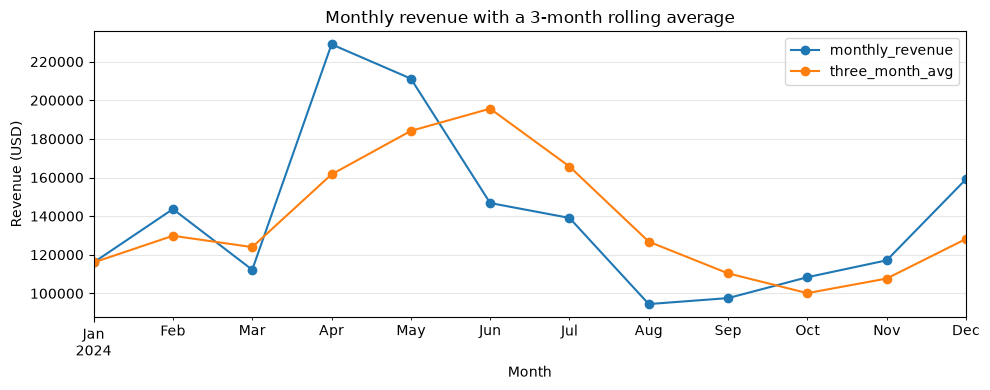

In [22]:
ax = trend.plot(
    figsize=(10, 4),
    marker="o",
    title="Monthly revenue with a 3-month rolling average",
)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (USD)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
weekday_revenue = (
    df.groupby("weekday")["revenue"].sum()
    .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
    .round(2)
)
weekday_revenue

weekday
Monday       218837.32
Tuesday      261846.23
Wednesday    166698.55
Thursday     321695.26
Friday       226175.33
Saturday     222901.13
Sunday       256395.33
Name: revenue, dtype: float64

## 12. Summary

In [24]:
total_revenue = float(df["revenue"].sum())
top_product = by_product["revenue"].idxmax()
best_region, best_manager = region_summary["attainment_pct"].idxmax()

print(f"Orders analysed : {len(df):,}")
print(f"Total revenue   : ${total_revenue:,.2f}")
print(f"Average order   : ${df['revenue'].mean():,.2f}")
print(f"Top product     : {top_product} (${by_product.loc[top_product, 'revenue']:,.2f})")
print(f"Best region     : {best_region} / {best_manager} "
      f"({region_summary['attainment_pct'].max():.1f}% of target)")
print(f"Missing values  : {int(df.isna().sum().sum())}")

Orders analysed : 500
Total revenue   : $1,674,549.15
Average order   : $3,349.10
Top product     : Mouse ($473,519.57)
Best region     : North / A. Rao (108.1% of target)
Missing values  : 0
